# Lesson 14. Which splat covers the pixel?

[Course plan](../../README.md)

A horizontal red splat and a vertical blue one lie on the same line of sight. The camera sees a cross. At the intersection both splats reach the same pixel, even though their centers are a full unit apart in space. That pixel gives us a way into the renderer.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Two orders, one camera

The left frame draws the nearer splat first. The right frame feeds the same shapes and colors through in reverse. From the front, the crossing looks redder in the left image. From the side the footprints separate and the frames almost agree. As the camera continues around the scene, blue becomes the front layer.

The camera angle traces a circle about $(0,0,4)$. A separate control moves the red splat itself along world $Z$. The $u$ field picks a column on the middle row. Isolating either splat leaves identical images on both sides.

In [2]:
display(demo.experiment(14, "en"))

## From a 3D center to one pixel's coverage

The frame is $65\times65$, with column and row indices from 0 to 64. At zero orbit angle the camera is at the world origin, looks along $+Z$, and has its principal point at $(32,32)$. Both centers, $(0,0,3.5)$ and $(0,0,4.5)$, project there. A smaller **depth in this camera's coordinates** puts a splat first. Turning the camera changes those depths.

Depth supplies the order. The matrix from the previous lesson supplies the footprint. Red has a horizontal world scale of $0.55$, depth $3.5$, and a focal length of $48$ pixels. Its screen scale is $48\cdot0.55/3.5=7.543$ pixels. The vertical scale is $48\cdot0.35/3.5=4.8$. Here the footprint axes line up with the screen axes, so we can calculate each component separately.

Six pixels to the right of center, the horizontal offset is $6/7.543\approx0.795$ splat widths. The vertical offset is zero. Squaring the distance in the splat's own units gives $q\approx0.795^2=0.633$. Its weight is $G=\exp(-q/2)\approx0.729$. Red's center opacity $o=0.6$ is dimensionless. Only the fraction $\alpha=oG\approx0.437$ contributes at this pixel. At the center $q=0$, the weight is one, and $\alpha=o$.

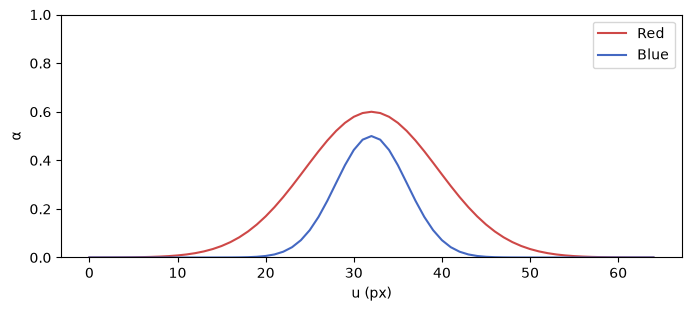

In [3]:
fig = demo.visibility_profile("en")
display(fig)
plt.close(fig)

## How much of the pixel is left?

An empty scene leaves one whole pixel available. We call the remaining fraction $T$ for transmittance, the share passed by the preceding layers. Red has $\alpha_1=0.6$ at the center. Its share is $1\cdot0.6=0.6$. The fraction left is $T=1\cdot(1-0.6)=0.4$. Blue has $\alpha_2=0.5$ and takes half of that remainder, $0.4\cdot0.5=0.2$. Another $0.4\cdot(1-0.5)=0.2$ goes to the white background.

Red is $(1,0,0)$, blue is $(0,0,1)$, and white is $(1,1,1)$. Each component ranges from zero to one. We multiply all three components by the layer's share, then add channel by channel.

$$
C=0.6(1,0,0)+0.2(0,0,1)+0.2(1,1,1)=(0.8,0.2,0.4).
$$

Reversing the order leaves the same share for the background. Blue now takes $0.5$ first and red gets $(1-0.5)0.6=0.3$. The result is $(0.5,0.2,0.7)$. The change is concentrated where both $\alpha$ values are large.

In [4]:
scene, camera = sr.overlap_scene(), sr.orbit_camera()
for u in (32, 38):
    remaining = 1.
    rgb = np.zeros(3)
    for item in sr.project_splats(scene, camera, 65, 65):
        alpha = sr.footprint_alpha([u, 32], item)
        rgb += remaining * alpha * item["color"]
        remaining *= 1 - alpha
    rgb += remaining * np.ones(3)
    np.testing.assert_allclose(rgb, sr.render_scene(scene, camera)[32, u])
    print(u, np.round(rgb, 6))

32 [0.8 0.2 0.4]
38 [0.905928 0.468656 0.562728]


## From the loop to a full frame

At pixel $p=(u,v)$ we start with a black accumulator $C=(0,0,0)$ and a remaining fraction $T=1$. At splat $i$ we add $T\alpha_i c_i$ to $C$, then replace $T$ with $T(1-\alpha_i)$. At the end we add $T c_{\rm bg}$, where $c_{\rm bg}$ is the background RGB. Uppercase $C$ belongs to the frame, lowercase $c_i$ to a single splat.

A tilted ellipse replaces two independent divisions with $q=\delta^\mathsf{T} S^{-1}\delta$. Here $\delta=p-m$ is the displacement in pixels from the projected center $m$; $S$ is screen covariance in squared pixels and $S^{-1}$ its inverse. The matrix first acts on the two-component offset. A dot product with the same offset then produces one dimensionless number. As before, the code uses it to compute $\alpha_i=o_i\exp(-q/2)$.

The camera drops centers at or behind its near depth of $0.05$, where dividing by depth no longer gives a useful footprint for this camera. It sorts the remaining centers once per frame. Two long intersecting ellipsoids can have different front edges along different rays. Center sorting gives them one order across the image. When two center depths nearly coincide, a change in order can cause a visible jump in color.

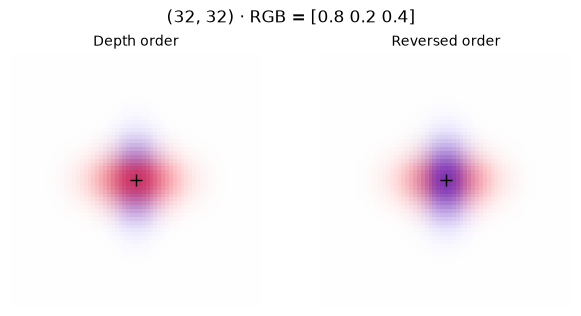

In [5]:
fig = demo.visibility_figure("en")
display(fig)
plt.close(fig)

## Experiments and worked answers

What happens at the center if blue disappears? From which angle does swapping the layers barely matter?

<details><summary>Worked answer</summary>

When $\alpha_2=0$, the result is $0.6(1,0,0)+0.4(1,1,1)=(1,0.4,0.4)$. From the side the footprints barely overlap, so one factor in $\alpha_1\alpha_2$ is small at nearly every pixel. Subtracting the two orders gives $\alpha_1\alpha_2(c_1-c_2)$, or $0.3(1,0,-1)$ at the center of the original example.

</details>